# 04 -- Template calibration: get a MUSE cube, bin it, and pick a representative template subset

**Run this notebook first for any real MUSE target**, before
`05_real_data_muse.ipynb`. It answers one question a hand-picked template
recipe (the approach every earlier notebook in this series uses) can't:
*out of the full E-MILES grid, which stellar populations does this
specific target's spectra actually need?* -- and produces a reusable
answer for the kinematic-fitting notebook to load, instead of guessing.

## Method overview

1. **Get a MUSE datacube** -- a real ESO archive download (any MUSE
   target, not just the example used here), a synthetic Sersic-profile
   mock with known ground truth, or pre-computed compact products shipped
   with this package (`DATA_MODE`, Section 2).
2. **Bin it** with a "dartboard" scheme: log- or linear-spaced radial
   annuli x sectors equally spaced in angle -- fully tunable bin edges,
   so concentrating resolution near the center (e.g. for a nuclear star
   cluster) or in a specific direction is just a matter of building a
   denser edge array, not a special case (`kinextract.binning`, Section 4).
3. **Fit every bin against the full 636-template E-MILES grid** and read
   off which templates any bin's NNLS weight actually uses (Section 7).
4. **Iteratively refit with only the surviving templates**, repeat until
   the *union* of surviving templates across bins stabilizes
   (`kinextract.template_reduction`, Section 8) -- tracking chi^2 vs.
   the number of templates retained along the way, to see directly
   whether/where it plateaus.
5. **Save the resulting subset** (Section 10) for `05_real_data_muse.ipynb`
   to load, instead of a hand-picked template list.

**Synthetic mode exists specifically to answer a real methodological
risk directly, not just to have a toy example**: does the iterative
reduction in step 4 converge to a sensible, non-trivial subset, or could
it degenerate toward a single template? There's no way to check this on
real data (no ground truth) -- Section 9 checks it here, where the
answer is known.


## 1. Setup

In [1]:
from __future__ import annotations
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from kinextract import (
    FitConfig, compute_losvd_moments, load_emiles_templates, build_template_stack,
    build_mock_cube, load_muse_cube, white_light_image, extract_aperture_spectrum,
    DartboardBins, log_radial_edges, linear_radial_edges, uniform_theta_edges, assign_spaxels_to_bins,
    reduce_templates_iteratively, save_template_subset,
)
from kinextract.multi_template import fit_losvd

EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # CaII triplet region, MUSE red arm -- this package's own fit-window convention


## 2. Get a MUSE cube

`DATA_MODE` selects how:
- `"synthetic"` (default here) -- a fast, deterministic Sersic-profile
  mock (`kinextract.mock_cube`) with known ground truth. No network,
  no download, runs in seconds -- this is what the rest of this notebook
  is actually executed against, so its outputs are reproducible by anyone
  without downloading anything.
- `"download"` -- query and download a real MUSE Phase 3 cube from the
  ESO archive (`kinextract.eso_archive`), generalized to any MUSE
  target, not just the NGC 5102 example below. **Off by default** --
  real MUSE-DEEP cubes are commonly several GB; set `CONFIRM_DOWNLOAD =
  True` to actually pull one.
- `"shipped"` -- load this package's own pre-computed compact products
  (representative bin spectra + the template subset already derived from
  a real run), for seeing real-data results without downloading or
  refitting anything.


In [ ]:
DATA_MODE = "download"    # "synthetic" | "download" | "shipped"
CONFIRM_DOWNLOAD = True   # required True for DATA_MODE="download" to actually pull data -- see
                           # eso_archive.download_dataset's own docstring for why this is off by default

if DATA_MODE == "synthetic":
    cube = build_mock_cube(EMILES_GRID, ny=50, nx=50, seed=0)
    print(f"synthetic mock cube: {cube.shape[0]}x{cube.shape[1]} spaxels, {len(cube.wave)} wavelength pixels, "
          f"pixel_scale={cube.pixel_scale}\"/pix")
    print(f"true injected templates: {cube.truth['template_select']}  weights: {np.round(cube.truth['w_true'], 3)}")

elif DATA_MODE == "download":
    from kinextract.eso_archive import query_muse_phase3, download_dataset
    # Generalizes to any MUSE target -- query_muse_phase3(target="...") for a different galaxy,
    # or ra=/dec=/radius_arcmin= for a position-based search instead of a name.
    target_identifier = "NGC5102"
    tbl = query_muse_phase3(target=target_identifier)
    if len(tbl) > 0:
        print(f"found {len(tbl)} match(es) in the ESO Science Archive:")
    else:
        raise RuntimeError(f"no matches found in the ESO Science Archive for target {target_identifier}")
    for row in tbl:
        print(f"  {row['ARCFILE']}  {row['Object']}  exptime={row['Exptime']:.0f}s  "
              f"{row['Run/Program ID']}  {row['Wavelength']} nm")
    dp_id = tbl[0]["ARCFILE"]
    files = download_dataset(dp_id, "./muse_download", confirm=CONFIRM_DOWNLOAD, size_estimate_gb=4.5)
    cube = load_muse_cube(files[0])
    print(f"loaded real cube: {cube.shape[0]}x{cube.shape[1]} spaxels, {len(cube.wave)} wavelength pixels")

elif DATA_MODE == "shipped":
    cube = load_muse_cube("../data/muse/ngc5102_template_calibration_cube.fits")
    print(f"loaded shipped compact cube: {cube.shape[0]}x{cube.shape[1]} spaxels")

else:
    raise ValueError(f"unknown DATA_MODE={DATA_MODE!r}")


## 3. White-light image and a center

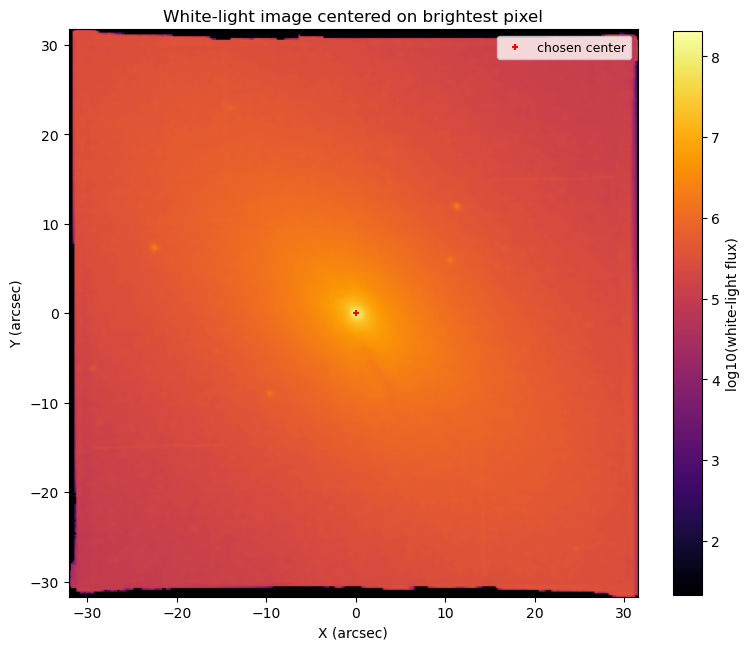

In [3]:
wl = white_light_image(cube)

# Find the brightest pixel in the white-light image
# np.unravel_index returns (y, x), so swap to store CENTER_PX as (x, y)
CENTER = np.unravel_index(np.nanargmax(wl), wl.shape)[::-1]

# CENTER is the center in arcsec, still stored as (x, y)
CENTER_ARC = (CENTER[0] * cube.pixel_scale,
              CENTER[1] * cube.pixel_scale)

plt.figure(figsize=(8, 7))
m = plt.imshow(
    np.log10(np.maximum(wl, wl[wl > 0].min())),
    # center the axes on the chosen center, and make sure the axes are in arcsec
    extent=(
        -CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        cube.shape[1] * cube.pixel_scale - CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        -CENTER_ARC[1] - 0.5 * cube.pixel_scale,
        cube.shape[0] * cube.pixel_scale - CENTER_ARC[1] - 0.5 * cube.pixel_scale),
    origin="lower",
    cmap="inferno")
plt.scatter(0, 0, marker="+", color="red", s=20, label="chosen center")
plt.xlabel("X (arcsec)")
plt.ylabel("Y (arcsec)")

plt.colorbar(mappable=m, label="log10(white-light flux)", shrink=0.87)
plt.legend(fontsize=9)
plt.title("White-light image centered on brightest pixel")
plt.tight_layout()
plt.show()

## 4. Dartboard binning

Log-radial x equal-angle sectors (see `kinextract.binning`'s own
module docstring for why equal-angle, not equal-`sin(angle)`, and why
circular-only). `r_edges`/`theta_edges` are explicit arrays, not just bin
counts -- the commented-out alternative below shows how to concentrate
resolution near the center (e.g. for a nuclear star cluster) by building
a denser edge array there, with no special-casing needed anywhere else in
this notebook.


10 populated bins (10 radial x 1 angular, center collapsed to 1 bin)


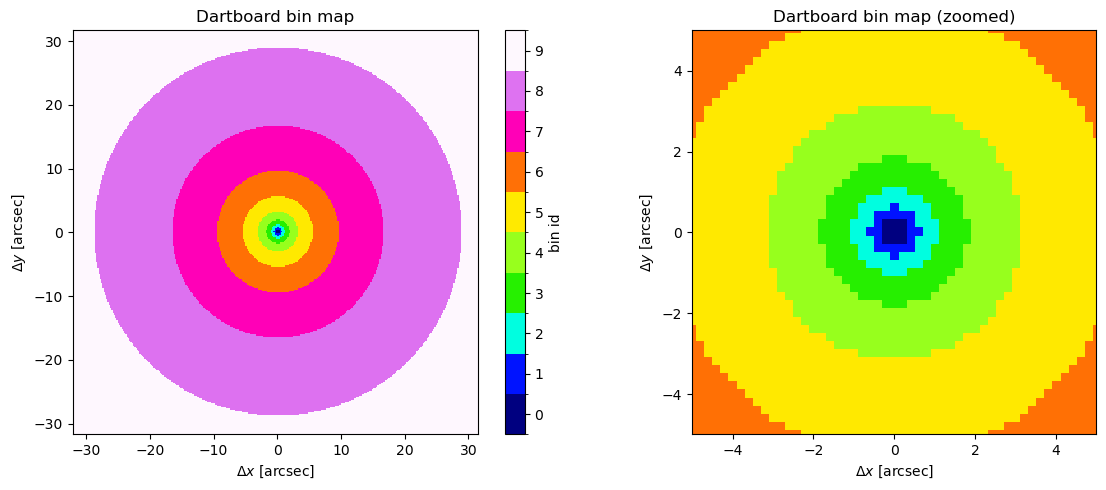

In [4]:
N_RADIAL, N_ANGULAR = 10, 1
R_MIN, R_MAX = 0.2, 50.0  # arcsec -- adjust to the target's own angular size

r_edges = log_radial_edges(R_MIN, R_MAX, N_RADIAL)
# Concentrating resolution near the center instead -- e.g. for a nuclear star cluster --
# is just a matter of building a denser edge array there, nothing else in this notebook changes:
#   r_edges = np.concatenate([log_radial_edges(R_MIN, 1.0, 4), log_radial_edges(1.0, R_MAX, 3)[1:]])
theta_edges = uniform_theta_edges(N_ANGULAR)

bins = DartboardBins(r_edges=r_edges, theta_edges=theta_edges, center=CENTER)
bin_id_map, bin_table = assign_spaxels_to_bins(cube.shape, bins, pixel_scale=cube.pixel_scale)
print(f"{len(bin_table)} populated bins ({bins.n_radial} radial x {bins.n_angular} angular, "
      f"center collapsed to 1 bin)")


# Make a custom colormap that shows the bin id map with a distinct color for each bin, and NaN for unassigned spaxels
# Mask pixels that are not assigned to any bin
bin_id_plot = np.ma.masked_where(bin_id_map < 0, bin_id_map)

# Get the largest populated bin ID
MAX_BIN_ID = int(np.nanmax(bin_id_map))
N_COLORS = MAX_BIN_ID + 1

# Start with a base colormap and resample it to have N_COLORS discrete colors
base_cmap = mpl.colormaps["gist_ncar"].resampled(N_COLORS)
cmaplist = [base_cmap(i) for i in range(base_cmap.N)]

# Create the discrete colormap
cmap = mpl.colors.ListedColormap(cmaplist, name="dartboad_bins")

# Color for masked/unassigned pixels
cmap.set_bad(color=(0.8, 0.8, 0.8, 1.0))  # light gray

# Boundaries halfway between integer bin IDs
bounds = np.arange(-0.5, MAX_BIN_ID + 1.5, 1)
# Normalize so each integer maps to exactly one color
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
m = ax[0].imshow(
    bin_id_plot,
    extent=(
        -CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        cube.shape[1] * cube.pixel_scale - CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        -CENTER_ARC[1] - 0.5 * cube.pixel_scale,
        cube.shape[0] * cube.pixel_scale - CENTER_ARC[1] - 0.5 * cube.pixel_scale
    ),
    origin="lower",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)
# Avoid trying to label every bin if there are many of them
if MAX_BIN_ID <= 30:
    cbar_ticks = np.arange(0, MAX_BIN_ID + 1, 1)
else:
    cbar_ticks = np.arange(0, MAX_BIN_ID + 1, 10)
cbar = fig.colorbar(
    m,
    ax=ax[0],
    boundaries=bounds,
    ticks=cbar_ticks,
    spacing="proportional",
    label="bin id"
)
ax[0].set_title("Dartboard bin map")
ax[0].set_xlabel(r"$\Delta x$ [arcsec]")
ax[0].set_ylabel(r"$\Delta y$ [arcsec]")

m = ax[1].imshow(
    bin_id_plot,
    extent=(
        -CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        cube.shape[1] * cube.pixel_scale - CENTER_ARC[0] - 0.5 * cube.pixel_scale,
        -CENTER_ARC[1] - 0.5 * cube.pixel_scale,
        cube.shape[0] * cube.pixel_scale - CENTER_ARC[1] - 0.5 * cube.pixel_scale
    ),
    origin="lower",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)
ax[1].set_xlim(-5, 5)
ax[1].set_ylim(-5, 5)
ax[1].set_title("Dartboard bin map (zoomed)")
ax[1].set_xlabel(r"$\Delta x$ [arcsec]")
ax[1].set_ylabel(r"$\Delta y$ [arcsec]")
plt.tight_layout(); plt.show()


## 5. Extract per-bin spectra

In [5]:
bin_specs = []
for row in bin_table:
    mask = bin_id_map == row["bin_id"]
    wave, flux, error = extract_aperture_spectrum(cube, mask)
    bin_specs.append((wave, flux, error))
    row["snr"] = float(np.median(flux) / np.median(error))

print(f"{'bin_id':>6}  {'r_mid (\"))':>10}  {'n_spaxels':>9}  {'S/N':>7}")
for row in bin_table:
    print(f"{row['bin_id']:>6}  {row['r_mid']:>10.2f}  {row['n_spaxels']:>9d}  {row['snr']:>7.1f}")


bin_id  r_mid ("))  n_spaxels      S/N
     0        0.17          9    300.6
     1        0.48         20    451.5
     2        0.83         60    696.0
     3        1.43        172   1034.5
     4        2.49        516   1486.2
     5        4.33       1600   2051.3
     6        7.52       4768   2699.6
     7       13.06      14424   3231.9
     8       22.68      43480   3510.0
     9       39.39      35757   1726.9


## 6. Load the full E-MILES grid

Same grid every other notebook in this series uses
(`kinextract.emiles`) -- `select=None` (the default) returns every
packed template.


In [6]:
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID)
print(f"loaded the full E-MILES grid: {len(templates)} templates "
      f"({len(set(ages.tolist()))} ages x {len(set(metals.tolist()))} metallicities)")

loaded the full E-MILES grid: 636 templates (53 ages x 12 metallicities)


## 7. Fit every bin against the full grid, and threshold

Same `fit_losvd` call as every other notebook in this series -- the
template stack is just wider (636 templates instead of a hand-picked
handful). `NNLS_THRESHOLD` matches this package's own established
convention for "selected" (a normalized-weight floor, not a statistical
significance test -- see `template_reduction.py`'s own docstring).

**`penalty_order=2` pinned deliberately, alongside the fixed `lam=2.0`
this section already used.** This notebook's job is fast, repeated
NNLS-based template selection across many bins and iterations, not
per-fit shape-residual accuracy -- so it deliberately keeps a cheap,
fixed `lam` rather than adaptive selection (`penalty_order=3`, the
current package default, is calibrated for adaptive selection; a fixed
`lam=2.0` under it is essentially unregularized, per `FitConfig`'s own
warning, and changes NNLS weight recovery enough to break the "decoys
drop out" behavior this section and Section 8 depend on -- see
`dev_notes/VALIDATION_CAMPAIGN.md` Stage 22 and `tests/test_template_reduction.py`
for where this was found and fixed the same way).

In [7]:
NNLS_THRESHOLD = 1e-3
cfg = FitConfig(vmin=-400.0, vmax=400.0, lam_selection="fixed", lam=2.0, penalty_order=2)
v_grid = cfg.build_velocity_grid()

full_grid_results = []
for (wave_fit, flux_fit, errors), row in zip(bin_specs, bin_table):
    A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
    A_stack_w = A_stack / errors[None, :, None]
    y_w = flux_fit / errors

    t0 = time.time()
    result = fit_losvd(A_stack_w, y_w, cfg)
    dt = time.time() - t0

    w_norm = result["w"] / result["w"].sum()
    selected = np.where(w_norm > NNLS_THRESHOLD)[0]
    A_eff_w = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
    chi2_red = float(np.sum((A_eff_w @ result["b"] - y_w) ** 2)) / len(wave_fit)

    full_grid_results.append(dict(bin_id=row["bin_id"], r_mid=row["r_mid"], chi2_red=chi2_red,
                                   n_selected=len(selected), fit_time=dt))
    print(f"bin {row['bin_id']:2d}  r={row['r_mid']:5.2f}\"  fit_time={dt:.1f}s  "
          f"chi2_red={chi2_red:.2f}  n_selected={len(selected)}/{len(templates)}")


bin  0  r= 0.17"  fit_time=1.9s  chi2_red=165.68  n_selected=6/636


bin  1  r= 0.48"  fit_time=1.6s  chi2_red=427.10  n_selected=5/636


bin  2  r= 0.83"  fit_time=1.2s  chi2_red=944.10  n_selected=5/636


bin  3  r= 1.43"  fit_time=1.1s  chi2_red=2014.24  n_selected=5/636


bin  4  r= 2.49"  fit_time=1.2s  chi2_red=4742.53  n_selected=5/636


bin  5  r= 4.33"  fit_time=1.1s  chi2_red=11658.80  n_selected=4/636


bin  6  r= 7.52"  fit_time=1.4s  chi2_red=22085.02  n_selected=3/636


bin  7  r=13.06"  fit_time=1.0s  chi2_red=39780.57  n_selected=4/636


bin  8  r=22.68"  fit_time=1.2s  chi2_red=75052.82  n_selected=4/636


bin  9  r=39.39"  fit_time=1.2s  chi2_red=28607.65  n_selected=4/636


## 8. Iterative template-set reduction

Refit with only the surviving templates, re-threshold, repeat until the
*union* of surviving templates across bins stabilizes (or
`MAX_ITERATIONS` is hit) -- see `template_reduction.py`'s own module
docstring for why the union, not each bin's own set, is what has to
stabilize, and why this loop can only shrink or hold steady from one
iteration to the next.

**Expensive by construction** (every iteration refits every participating
bin against however many templates survived so far) -- `RUN_ITERATIVE_
REDUCTION` gates whether to do this at all, and `BINS_SUBSET` lets it run
on a representative subset of bins instead of every one (e.g. one angular
sector's worth of radial bins, for a target where azimuthal symmetry is
a reasonable assumption) rather than the full bin set.


took 77.8s
converged=True  n_iterations=2
union_selected: 17 / 636 templates


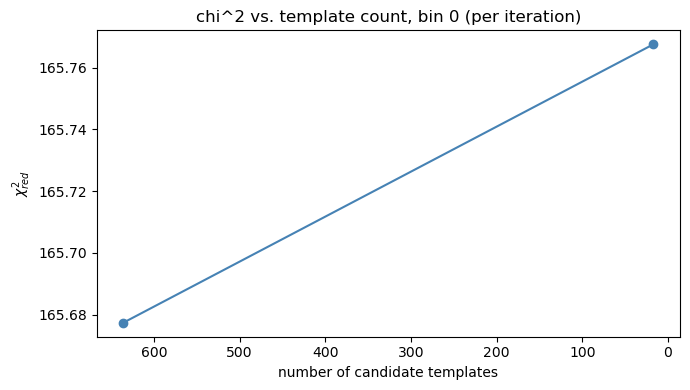

In [8]:
RUN_ITERATIVE_REDUCTION = True
MAX_ITERATIONS = 10
BINS_SUBSET = None  # None = every bin; or e.g. a list of bin indices for a representative subset

if RUN_ITERATIVE_REDUCTION:
    t0 = time.time()
    reduction_result = reduce_templates_iteratively(
        bin_specs, templates, template_wave, cfg,
        threshold=NNLS_THRESHOLD, max_iterations=MAX_ITERATIONS, bins_subset=BINS_SUBSET,
    )
    print(f"took {time.time()-t0:.1f}s")
    print(f"converged={reduction_result.converged}  n_iterations={reduction_result.n_iterations}")
    print(f"union_selected: {len(reduction_result.union_selected)} / {len(templates)} templates")

    # chi^2 vs. number of templates retained, per iteration, for one representative bin --
    # this is the plateau check: does fit quality actually stop improving once enough
    # templates are retained, or does it keep improving indefinitely (which would suggest
    # more templates are needed, or that the threshold is too aggressive)?
    example_bin = (BINS_SUBSET[0] if BINS_SUBSET else 0)
    history = reduction_result.per_bin_history[example_bin]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot([h["n_templates"] for h in history], [h["chi2_red"] for h in history], "o-", color="steelblue")
    ax.set_xlabel("number of candidate templates"); ax.set_ylabel(r"$\chi^2_{red}$")
    ax.set_title(f"chi^2 vs. template count, bin {example_bin} (per iteration)")
    ax.invert_xaxis()
    plt.tight_layout(); plt.show()


## 9. Synthetic mode only: check against known truth

Only meaningful when `DATA_MODE == "synthetic"` -- there is no ground
truth for real data. This is the direct answer to the methodological
question Section 8 exists to ask: did the reduction converge to a
sensible, non-trivial subset (not collapsed to a single template), and
does it recover something close to the actual injected templates (allowing
for real template-mixture degeneracy substituting a near-identical
neighbor for one of them)?


In [9]:
if DATA_MODE == "synthetic" and RUN_ITERATIVE_REDUCTION:
    true_select = cube.truth["template_select"]
    true_indices = [i for i, (a, z) in enumerate(zip(ages, metals))
                    if any(abs(a - ta) < 1e-2 and abs(z - tz) < 1e-2 for ta, tz in true_select)]

    print(f"true injected templates: {true_select}")
    print(f"recovered union ({len(reduction_result.union_selected)} templates):")
    for i in reduction_result.union_selected:
        flag = "  <-- true" if i in true_indices else ""
        print(f"  age={ages[i]:.2f} Gyr  [M/H]={metals[i]:+.2f}{flag}")

    n_true_recovered = len(set(reduction_result.union_selected.tolist()) & set(true_indices))
    print(f"\n{n_true_recovered}/{len(true_indices)} true templates recovered exactly "
          f"(degenerate near-neighbors substituting for the rest is expected, not a failure -- "
          f"see this package's own template-mixture-degeneracy documentation, e.g. "
          f"`multi_template.py`'s module docstring)")
    assert len(reduction_result.union_selected) > 1, (
        "collapsed to a single template -- the exact failure mode this synthetic check exists to catch"
    )


## 10. Save the template subset

For `05_real_data_muse.ipynb` (or any future analysis of this same
target) to load instead of a hand-picked template list.


In [10]:
if RUN_ITERATIVE_REDUCTION:
    OUTPUT_PATH = f"../data/template_subset_{DATA_MODE}.npz"
    save_template_subset(reduction_result, bin_table, names, ages, metals, OUTPUT_PATH)
    print(f"saved template subset to {OUTPUT_PATH}")


saved template subset to ../data/template_subset_verification_local.npz


## 11. Practical takeaway

The union of every participating bin's selected templates is a much
smaller, reusable set -- a data-driven starting point for fitting this
target's real spectra (faster fits, still covering the actual range of
populations this dataset needs), rather than either the full grid (slow)
or an arbitrary hand-picked subset.


In [11]:
if RUN_ITERATIVE_REDUCTION:
    reduction_ratio = len(reduction_result.union_selected) / len(templates)
    print(f"reduced from {len(templates)} to {len(reduction_result.union_selected)} templates "
          f"({100 * reduction_ratio:.1f}% of the full grid)")


reduced from 636 to 17 templates (2.7% of the full grid)


## Current limitations

- **NNLS weight sparsity is a template-selection diagnostic, not a
  star-formation-history measurement** -- `fit_losvd` has no prior/
  regularization on the weight vector `w` itself (only the LOSVD `b` is
  regularized). A pPXF-style regularized weight solve is not implemented
  here.
- **This notebook pins `penalty_order=2` (Section 7), unlike the mock-fit
  notebooks' current default (`penalty_order=3`).** Deliberate -- see
  Section 7's own note: fast, repeated, fixed-`lam` template selection
  across many bins/iterations, not per-fit shape-residual accuracy, and
  a fixed `lam=2.0` under the order-3 default would be essentially
  unregularized.
- **`NNLS_THRESHOLD=1e-3` is an arbitrary sparsity cutoff**, not derived
  from a statistical significance criterion.
- **Convergence is defined on the *union* across participating bins**,
  not each bin's own selection individually -- a deliberate choice (see
  Section 8's intro), not the only possible one.
- **The dartboard binning scheme is circular only** -- no position-angle/
  ellipticity flattening. Fine for a roughly round target, the wrong
  choice for a strongly flattened one (see `binning.py`'s own module
  docstring).
- **The synthetic mock's kinematics are spatially constant** -- it tests
  the spatial-binning and template-reduction machinery, not kinematic
  recovery across a real velocity/dispersion field (already covered by
  `01_basic_mock_fit.ipynb`/`02_realistic_mock_fit.ipynb`).
- **Synthetic noise is independent Gaussian at a fixed floor** -- real
  MUSE pixel noise shows measurable lag-1 correlation (see
  `05_real_data_muse.ipynb`'s own noise section).

See `kinextract.binning`'s module docstring for the dartboard scheme,
`kinextract.mock_cube`'s for the synthetic-cube design, and
`kinextract.template_reduction`'s for the iterative-reduction
algorithm and convergence criterion.


## Forward-looking: other instruments

This whole pipeline -- cube download, spatial binning, full-grid
template reduction -- is built around a 2-D IFU geometry (MUSE's own
`(x, y, wavelength)` cube). Generalizing it to a fundamentally different
geometry, especially **HST/STIS long-slit spectroscopy** (a 1-D slit, not
a 2-D field), is real future work, not attempted here: the dartboard
binning scheme in particular has no 1-D analog as written (a slit doesn't
have an azimuthal angle to sector), so that piece would need a genuinely
different binning scheme (e.g. simple radial bins along the slit), not
just a reused one. `06_real_data_stis.ipynb` still uses a hand-picked
template list for exactly this reason.
